# Momentum Trading Backtest
## Research question
Can a strategy that invests in the strongest-performing US market sectors outperform S&P 500?

## 1. Importing the required libraries 

In [19]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Defining the investment universe
The strategy will compare the eleven major US-stock market sectors. Each sector is represented by an exchange-traded fund (ETF). The S&P500, SPY, will be used as the benchmark.

In [20]:
sector_etfs = [
    "XLK", # Technology
    "XLF", # Financials
    "XLE", # Energy
    "XLV", # Healthcare
    "XLI", # Industrials
    "XLY", # Consumer Discretionary
    "XLP", # Consumer Staples
    "XLU", # Utilities
    "XLB", # Materials
    "XLRE", # Real Estate
    "XLC", # Communication Services
] 
benchmark= "SPY"
print(sector_etfs)
print(benchmark)

['XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB', 'XLRE', 'XLC']
SPY


## 3. Downloading historical market data
Daily adjusted closing prices are downloaded for the sectors ETFs and the S&P500 benchmark. Adjusted prices account for events such as dividends and stock splits.

In [21]:
all_tickers = sector_etfs + [benchmark]
prices = yf.download (
    all_tickers,
    start = "2018-07-01",
    end = "2026-10-01",
    auto_adjust = True,
    progress = False
) ["Close"]
prices.head()

Ticker,SPY,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,,
2018-07-02,240.102676,24.461826,45.941723,26.246252,22.878780,62.666424,32.480968,41.052429,24.595503,20.246288,72.745132,50.621624
2018-07-03,239.254822,24.419479,45.379433,26.411121,22.673285,62.465641,32.096344,41.148579,24.739201,20.304317,72.918915,50.367249
2018-07-05,241.206650,24.631227,46.070759,26.383062,22.724657,62.771179,32.550488,41.717537,25.064423,20.412655,73.674850,50.617004
2018-07-06,243.246780,24.754047,46.798973,26.544420,22.835966,62.989376,32.930500,41.845745,25.170301,20.571278,74.734917,51.014755
2018-07-09,245.437088,24.974272,47.066292,26.940813,23.358278,64.159126,33.180733,41.685486,24.935843,19.936773,75.282349,51.625278


## 4. Inspecting and validating the data 
Our downloaded dataset is checked for its size, date range and missing observations before calculating returns.
No missing values were identified, so no observations needed to be removed or estimated.

In [22]:
print("Number of rows and coloumn:", prices.shape)
print("First date:", prices.index.min())
print("last date:", prices.index.max())
print("/nMissing values in each ETF:")
print(prices.isna().sum())

Number of rows and coloumn: (2073, 12)
First date: 2018-07-02 00:00:00
last date: 2026-09-30 00:00:00
/nMissing values in each ETF:
Ticker
SPY     0
XLB     0
XLC     0
XLE     0
XLF     0
XLI     0
XLK     0
XLP     0
XLRE    0
XLU     0
XLV     0
XLY     0
dtype: int64


## 5. Converting daily prices into monthly prices
Because our strategy rebalances monthly, the final available closing price from each month is selected.

In [23]:
monthly_prices = prices.resample("ME").last()
monthly_prices.head()

Ticker,SPY,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,,
2018-07-31,248.466415,25.296143,44.669659,27.053066,23.931963,67.144470,32.865623,42.927547,24.996351,20.424259,77.272148,51.463398
2018-08-31,256.397461,25.101320,45.333347,26.112942,24.257330,67.301582,35.034416,43.095844,25.601404,20.687349,80.617462,54.090439
2018-09-30,257.921906,24.650648,45.289677,26.751667,23.719919,68.766998,35.027660,43.521278,24.923969,20.553228,82.999077,54.377365
2018-10-31,240.098343,22.386852,42.553810,23.721182,22.601864,61.293846,32.223774,44.392841,24.526531,20.959211,77.372742,48.884876
2018-11-30,244.551880,23.237907,41.601803,23.350317,23.195292,63.627018,31.591389,45.401585,25.871704,21.700930,83.627129,50.095638


## 6. Calculating monthly returns
Monthly returns measure the percentage change between one months end price and the next.

In [24]:
monthly_returns = monthly_prices.pct_change()
(monthly_returns.head()*100) .round(2)

Ticker,SPY,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,,
2018-07-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-08-31,3.19,-0.77,1.49,-3.48,1.36,0.23,6.60,0.39,2.42,1.29,4.33,5.10
2018-09-30,0.59,-1.80,-0.10,2.45,-2.22,2.18,-0.02,0.99,-2.65,-0.65,2.95,0.53
2018-10-31,-6.91,-9.18,-6.04,-11.33,-4.71,-10.87,-8.00,2.00,-1.59,1.98,-6.78,-10.10
2018-11-30,1.85,3.80,-2.24,-1.56,2.63,3.81,-1.96,2.27,5.48,3.54,8.08,2.48


## 7. Calculate the momentum signal 
For each sector ETF, momentum is a measure of its total percentage return over the previous 12-months. A higher value represents a stronger historical perfomance.

In [25]:
momentum_12m = monthly_prices[sector_etfs].pct_change(periods=12)
(momentum_12m.iloc[12:17]*100).round(2) 

Ticker,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,XLC
Date,,,,,,,,,,,
2019-07-31,15.55,3.20,-15.97,4.18,3.32,9.99,14.23,16.56,-0.20,17.32,5.85
2019-08-31,6.73,-2.98,-20.19,-0.74,0.35,3.66,16.25,20.93,-2.27,20.06,1.74
2019-09-30,8.43,3.73,-19.03,-3.69,1.17,4.43,17.13,26.90,2.68,24.56,2.05
2019-10-31,22.46,11.58,-10.60,8.61,14.80,16.31,14.34,23.50,13.04,26.54,11.02
2019-11-30,31.62,14.22,-7.72,5.52,15.56,15.00,13.34,17.05,12.36,17.89,17.92


## 8. Ranking sectors by momentum
Each month, the sector ETFs are ranked using their 12-month momentum. Rank 1 represents the strongest performing sector.

In [26]:
momentum_ranks = momentum_12m.rank(
    axis=1,
    ascending = False,
    method = "first"
)
momentum_ranks.iloc[12:17]

Ticker,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,XLC
Date,,,,,,,,,,,
2019-07-31,3.0,9.0,11.0,7.0,8.0,5.0,4.0,2.0,10.0,1.0,6.0
2019-08-31,4.0,10.0,11.0,8.0,7.0,5.0,3.0,1.0,9.0,2.0,6.0
2019-09-30,4.0,6.0,11.0,10.0,9.0,5.0,3.0,1.0,7.0,2.0,8.0
2019-10-31,3.0,8.0,11.0,10.0,5.0,4.0,6.0,2.0,7.0,1.0,9.0
2019-11-30,1.0,7.0,11.0,10.0,5.0,6.0,8.0,4.0,9.0,3.0,2.0


## 9. Selecting top 3 sectors
The strategy selects the three ETFs with the higher 12-month momentum and assigns an equal one-third weight to each.

In [27]:
top_three = momentum_ranks <= 3
target_weights = top_three.astype(float)/3 
target_weights.iloc[12:17]

Ticker,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,XLC
Date,,,,,,,,,,,
2019-07-31,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.333333,0.0,0.333333,0.000000
2019-08-31,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.333333,0.0,0.333333,0.000000
2019-09-30,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.333333,0.0,0.333333,0.000000
2019-10-31,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.333333,0.0,0.333333,0.000000
2019-11-30,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.333333,0.333333


## 10. Preventing look-ahead bias
Sector rankings calculated at the end of one month can only be used for the following month. The portfolio weights are therefore shifted forward by one month.

In [28]:
portfolio_weights = target_weights.shift(1)
portfolio_weights.iloc[12:18]

Ticker,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,XLC
Date,,,,,,,,,,,
2019-07-31,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000
2019-08-31,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.333333,0.0,0.333333,0.000000
2019-09-30,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.333333,0.0,0.333333,0.000000
2019-10-31,0.000000,0.0,0.0,0.0,0.0,0.0,0.333333,0.333333,0.0,0.333333,0.000000
2019-11-30,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.333333,0.0,0.333333,0.000000
2019-12-31,0.333333,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.333333,0.333333


# 11. Calculating the strategie's monthly returns
Each sector's monthly return is multiplied by its portfolio weight. The weighted returns are then added together to calculate the strategies total monthly return before transaction costs.

In [29]:
weighted_sector_returns = (
    portfolio_weights * monthly_returns[sector_etfs])
gross_strategy_returns = weighted_sector_returns.sum(axis = 1)
invested_months = portfolio_weights.sum(axis = 1) > 0
gross_strategy_returns =  gross_strategy_returns[invested_months]
gross_strategy_returns.name = "Momentum Strategy"
(gross_strategy_returns.head() * 100).round(2) 


Date
2019-08-31    2.79
2019-09-30    2.34
2019-10-31   -0.40
2019-11-30    0.59
2019-12-31    2.57
Freq: ME, Name: Momentum Strategy, dtype: float64

## 12. Accounting for transaction costs
Portfolio turnover measures how much the portfolio allocation changes each month. A transaction cost of 0.10% is applied to the value traded.

In [30]:
turnover = portfolio_weights.diff().abs().sum(axis = 1)
transaction_cost_rate = 0.001
transaction_costs = turnover * transaction_cost_rate
net_strategy_returns = ( gross_strategy_returns - transaction_costs.loc[gross_strategy_returns.index])
net_strategy_returns.name = "Momentum Strategy"
(net_strategy_returns.head() * 100).round(2)

Date
2019-08-31    2.69
2019-09-30    2.27
2019-10-31   -0.40
2019-11-30    0.52
2019-12-31    2.51
Freq: ME, Name: Momentum Strategy, dtype: float64

## 13. Creating the benchmark comparison
The strategys net monthly returns are compared with SPY, an ETF that tracks the S&P 500. Both return series are aligned over the same intvestment period.

In [31]:
benchmark_returns = monthly_returns[benchmark].loc[net_strategy_returns.index]
benchmark_returns.name = "S&P 500"
comparison_returns = pd.concat([net_strategy_returns, benchmark_returns], axis=1).dropna()
(comparison_returns.head() * 100).round(2)

,Momentum Strategy,S&P 500
Date,,
2019-08-31,2.69,-1.67
2019-09-30,2.27,1.95
2019-10-31,-0.40,2.21
2019-11-30,0.52,3.62
2019-12-31,2.51,2.91


## 14. Calculating cumulitive perfomance
Monthly returns are compounded to show how an initial investment of £100 would have changed over the full backtest period.

In [32]:
growth_of_100 = ( 1 + comparison_returns).cumprod() * 100
growth_of_100.head().round(2)

,Momentum Strategy,S&P 500
Date,,
2019-08-31,102.69,98.33
2019-09-30,105.02,100.24
2019-10-31,104.60,102.45
2019-11-30,105.14,106.16
2019-12-31,107.78,109.25


## 15. Visualising cumulative perfomance
The chart compares the growth of £100 invested in the momentum strategy with £100 invested in the S&P 500.

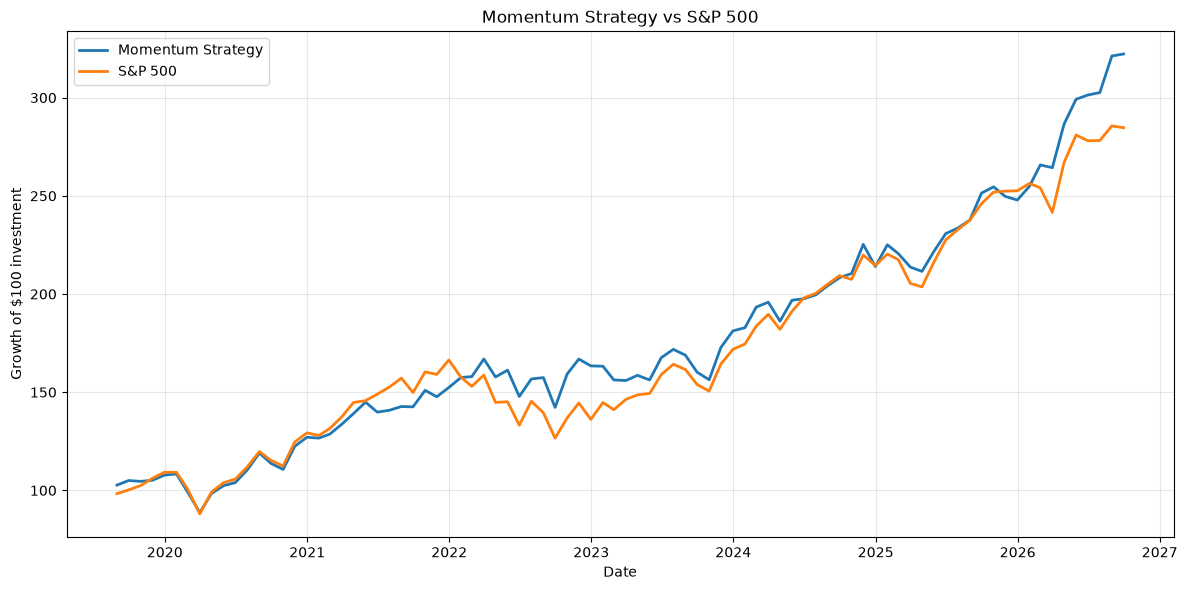

In [33]:
plt.figure(figsize = (12, 6))
plt.plot(
    growth_of_100.index,
    growth_of_100["Momentum Strategy"],
    label = "Momentum Strategy",
    linewidth= 2
)
plt.plot(
    growth_of_100.index,
    growth_of_100["S&P 500"],
    label = "S&P 500",
    linewidth = 2
)
plt.title("Momentum Strategy vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Growth of $100 investment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Calculating perfomance metrics
The strategy and benchmark are evaluated using annualised return, annualised volatility and the sharpe ratio. For simplicity, the sharpe ratio assumes a risk free rate of zero.

In [34]:
number_of_months = len(comparison_returns)
annualised_return = (
( 1 + comparison_returns).prod() ** (12 / number_of_months) - 1)
annualised_volatility = (
    comparison_returns.std() * np.sqrt(12))
sharpe_ratio = (comparison_returns.mean() / comparison_returns.std() * np.sqrt(12))
perfomance_summary = pd.DataFrame ({
    "Annualised Return (%)" : annualised_return * 100,
    "Annualised Volatility (%)" : annualised_volatility * 100,
    "Sharpe Ratio" : sharpe_ratio })
perfomance_summary.round(2)


,Annualised Return (%),Annualised Volatility (%),Sharpe Ratio
Momentum Strategy,17.74,15.42,1.14
S&P 500,15.72,16.42,0.98


## 17. Calculating maximum drawdown
Maximum drawdown measures the largest percentage decline from a previous portfolio peak. It shows the worst historical loss an investor would have experienced before the portfolio recovered.

In [35]:
running_peak = growth_of_100.cummax().clip(lower = 100)
drawdown = (growth_of_100 / running_peak - 1) 
maximum_drawdown = drawdown.min()
perfomance_summary ["Maximum Drawdown (%)"] = ( maximum_drawdown * 100)
perfomance_summary.round(2)

,Annualised Return (%),Annualised Volatility (%),Sharpe Ratio,Maximum Drawdown (%)
Momentum Strategy,17.74,15.42,1.14,-18.15
S&P 500,15.72,16.42,0.98,-23.93


## 18. Visualising Drawdowns
The drawdown chart shows the percentage by which investment was below its previous highest value throughout the backtest.

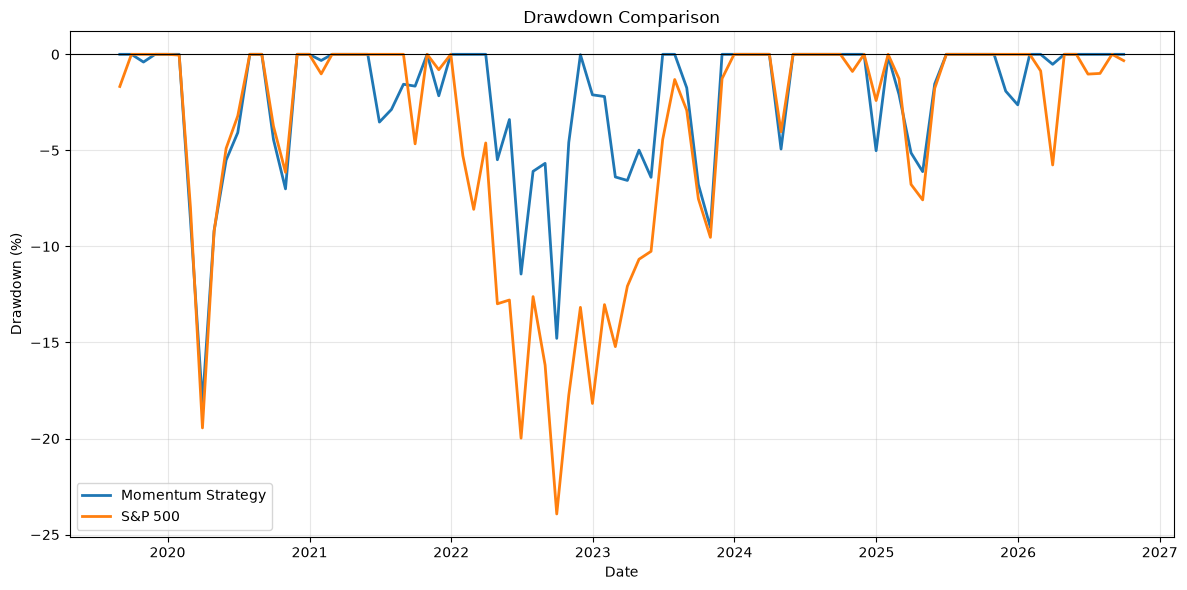

In [36]:
plt.figure(figsize = (12,6))
plt.plot(
    drawdown.index,
    drawdown ["Momentum Strategy"] * 100,
    label = "Momentum Strategy",
    linewidth = 2 )
plt.plot(drawdown.index,
         drawdown["S&P 500"] * 100,
         label = "S&P 500",
         linewidth = 2 )
plt.axhline( 0 , color = "black", linewidth = 0.8)
plt.title("Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

## 19. Conclusion and limitations
### Conclusion
Over the backtest period, i found that the momentum strategy outperfomed the S&P 500 after applying estimated transaction costs. It produced an annualised return of 17.7%, compared with 15.72% for the benchmark. The strategy also exhibited lower annualised volatility and a smaller maximum drawdown. Its sharpe ratio of 1.14 ended up exceeding the S&P 500's sharpe ratio of 0.98, which indicated a better risk-adjusted perfomance during the period tested. These results suggest that allocating equally to all three sectors with the strongest 12-month perfomance was effective with this sample. However, historical outperfomance does not guarantee that this strategy will perform like this in the future.
### Limitations
- This backtest covers a relatively short period, beginning in 2019.
- It also uses a fixed 12-month momentum period and only selects three sectors.
- Transaction costs are estimated at a constant rate which may actually differ from real trading costs.
- Taxes, bid-ask spreads and market slippage are not modelled seperately.
- The strategy was only tested on US sector ETFs.
- These results could be sensitive to the selected period and stratedy parameters.